# 01 - Sessions and funnel

**Goal.** Describe how players play (how many sessions, how long, how many events) and where they stop in the core progression (funnel).

**Approach.** A session is one `user_session_id`. All queries run on the `events` view created by `scripts/load_events.py`; no data is copied except the small `sessions` table built below.

In [1]:
import sys
sys.path.append("../scripts")
from load_events import connect_events
import matplotlib.pyplot as plt

con, readable, unreadable = connect_events("../data/raw/player_analytics/*.parquet")
print(len(readable), "readable files,", len(unreadable), "unreadable")

67 readable files, 1 unreadable


## 1. Events without a session id

Some events carry an empty `user_session_id` (they look server-side: currency, achievements, identity). They cannot belong to a session, so they are excluded from the session table. First, how many are there?

In [2]:
con.sql("""
    SELECT event_name,
           COUNT(*) AS events_without_session
    FROM events
    WHERE user_session_id = ''
    GROUP BY 1
    ORDER BY 2 DESC
    LIMIT 10
""").show(max_width=200)

con.sql("""
    SELECT ROUND(100.0 * COUNT(*) FILTER (WHERE user_session_id = '') / COUNT(*), 1) AS pct_events_without_session
    FROM events
""").show()

┌───────────────────────┬────────────────────────┐
│      event_name       │ events_without_session │
│        varchar        │         int64          │
├───────────────────────┼────────────────────────┤
│ achievementUpdated    │                3525219 │
│ currencyGranted       │                1851102 │
│ currencySpent         │                1536815 │
│ itemsGranted          │                 234525 │
│ achievementClaimed    │                 155432 │
│ _identityCreate       │                  51743 │
│ _experimentJoin       │                   3379 │
│ energyModifierGranted │                    429 │
└───────────────────────┴────────────────────────┘

┌────────────────────────────┐
│ pct_events_without_session │
│           double           │
├────────────────────────────┤
│                       10.4 │
└────────────────────────────┘



## 2. The `sessions` table

One row per session: player, start, end, duration, number of events. The table is small (about 275,000 rows) and is kept in memory.

In [3]:
con.execute("""
    CREATE OR REPLACE TABLE sessions AS
    SELECT user_session_id,
           user_id,
           MIN(ts)                                   AS started_at,
           MAX(ts)                                   AS ended_at,
           DATE_DIFF('second', MIN(ts), MAX(ts))     AS duration_s,
           COUNT(*)                                  AS n_events
    FROM events
    WHERE user_session_id <> ''
    GROUP BY 1, 2
""")
con.sql("SELECT COUNT(*) AS sessions, COUNT(DISTINCT user_session_id) AS distinct_ids FROM sessions").show()

┌──────────┬──────────────┐
│ sessions │ distinct_ids │
│  int64   │    int64     │
├──────────┼──────────────┤
│   275697 │       275697 │
└──────────┴──────────────┘



If `sessions` and `distinct_ids` differ, one session id is shared by several players: investigate before going further.

## 3. Session duration

Durations are very skewed, so the median and percentiles are shown, not only the mean.

In [4]:
con.sql("""
    SELECT COUNT(*)                                  AS sessions,
           QUANTILE_CONT(duration_s, 0.5)            AS median_s,
           QUANTILE_CONT(duration_s, 0.9)            AS p90_s,
           QUANTILE_CONT(duration_s, 0.99)           AS p99_s,
           ROUND(AVG(duration_s), 0)                 AS mean_s,
           COUNT(*) FILTER (WHERE duration_s = 0)    AS zero_duration,
           COUNT(*) FILTER (WHERE duration_s > 86400) AS longer_than_24h
    FROM sessions
""").show(max_width=200)

┌──────────┬──────────┬────────┬───────────────────┬────────┬───────────────┬─────────────────┐
│ sessions │ median_s │ p90_s  │       p99_s       │ mean_s │ zero_duration │ longer_than_24h │
│  int64   │  double  │ double │      double       │ double │     int64     │      int64      │
├──────────┼──────────┼────────┼───────────────────┼────────┼───────────────┼─────────────────┤
│   275697 │    568.0 │ 3891.0 │ 34186.35999999929 │ 2186.0 │         12601 │             437 │
└──────────┴──────────┴────────┴───────────────────┴────────┴───────────────┴─────────────────┘



Sessions of duration 0 contain a single timestamp (for example an app opened and closed at once). Sessions longer than 24 hours span two calendar days: keep them in mind when reading durations.

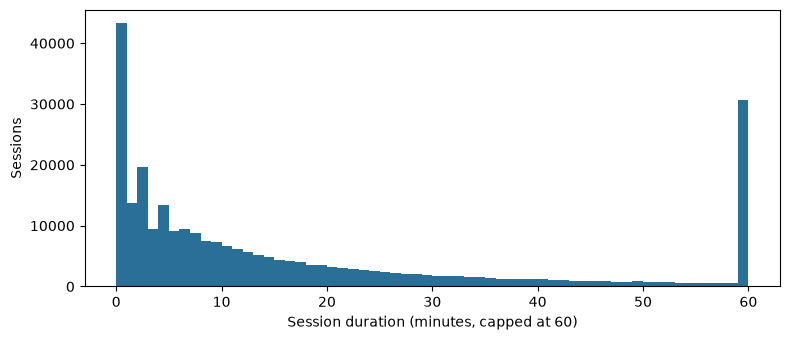

In [5]:
df_dur = con.execute("SELECT LEAST(duration_s, 3600) / 60.0 AS minutes FROM sessions").df()
ax = df_dur["minutes"].plot.hist(bins=60, figsize=(8, 3.5), color="#2a6f97")
ax.set_xlabel("Session duration (minutes, capped at 60)")
ax.set_ylabel("Sessions")
plt.tight_layout()
plt.show()

## 4. Daily active players and sessions per player

The first day (2025-02-28) is partial (data starts at 05:58) and 2025-03-27 shows an unexplained drop: both are marked on the chart.

In [6]:
df_day = con.execute("""
    SELECT CAST(started_at AS DATE)                                  AS day,
           COUNT(DISTINCT user_id)                                   AS dau,
           ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT user_id), 2)        AS sessions_per_player
    FROM sessions
    GROUP BY 1
    ORDER BY 1
""").df()
df_day.head()

,day,dau,sessions_per_player
0,2025-02-28,2620,1.48
1,2025-03-01,4918,1.79
2,2025-03-02,4733,1.75
3,2025-03-03,4012,1.68
4,2025-03-04,4462,1.73


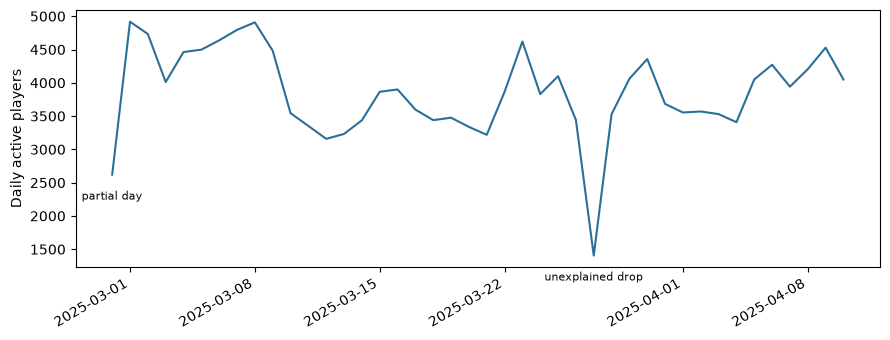

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df_day["day"], df_day["dau"], color="#2a6f97")
for d, label in [("2025-02-28", "partial day"), ("2025-03-27", "unexplained drop")]:
    row = df_day[df_day["day"].astype(str) == d]
    if len(row):
        ax.annotate(label, (row["day"].iloc[0], row["dau"].iloc[0]),
                    xytext=(0, -18), textcoords="offset points", ha="center", fontsize=8)
ax.set_ylabel("Daily active players")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Funnel

A funnel counts, at each step, how many players reached it **after** the previous step. The steps below follow the core progression observed in the event list (module E documents them):

1. `gameOpened`: the player opened the game
2. `tokenCashout`: first core-loop reward
3. `deviceUnlocked`: first new device unlocked
4. `zoneUnlocked`: first new zone unlocked
5. `purchaseCompleted`: first in-app purchase

The order is checked on the first timestamp of each step. The step names are an interpretation of the event names, not documented game design: say so if asked.

In [8]:
STEPS = ["gameOpened", "tokenCashout", "deviceUnlocked", "zoneUnlocked", "purchaseCompleted"]
names = ", ".join(f"'{s}'" for s in STEPS)

con.execute(f"""
    CREATE OR REPLACE TABLE firsts AS
    SELECT user_id, event_name, MIN(ts) AS t
    FROM events
    WHERE event_name IN ({names})
    GROUP BY 1, 2
""")

# step k keeps the players of step k-1 whose first event k happened at or after step k-1
con.execute("CREATE OR REPLACE TABLE funnel_users AS SELECT user_id, t, 1 AS step FROM firsts WHERE event_name = ?", [STEPS[0]])
for k in range(1, len(STEPS)):
    con.execute(f"""
        INSERT INTO funnel_users
        SELECT f.user_id, f.t, {k + 1}
        FROM firsts f
        JOIN funnel_users p ON p.user_id = f.user_id AND p.step = {k} AND f.t >= p.t
        WHERE f.event_name = '{STEPS[k]}'
    """)

df_funnel = con.execute("SELECT step, COUNT(*) AS players FROM funnel_users GROUP BY 1 ORDER BY 1").df()
df_funnel["event"] = STEPS[: len(df_funnel)]
df_funnel["pct_of_previous"] = (100 * df_funnel["players"] / df_funnel["players"].shift(1)).round(1)
df_funnel["pct_of_first"] = (100 * df_funnel["players"] / df_funnel["players"].iloc[0]).round(1)
df_funnel[["event", "players", "pct_of_previous", "pct_of_first"]]

,event,players,pct_of_previous,pct_of_first
0,gameOpened,68881,NaN,100.0
1,tokenCashout,63207,91.8,91.8
2,deviceUnlocked,55784,88.3,81.0
3,zoneUnlocked,52140,93.5,75.7
4,purchaseCompleted,777,1.5,1.1


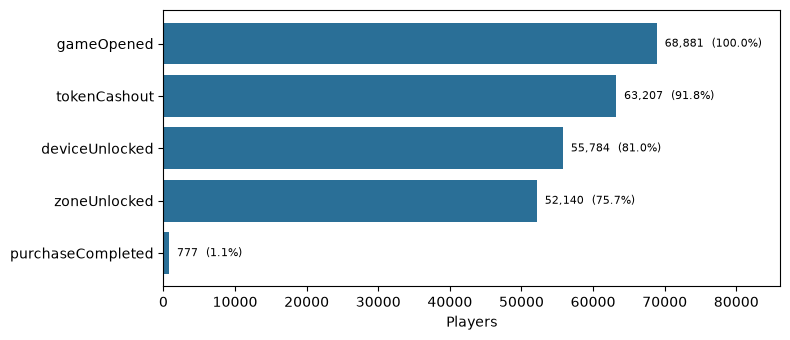

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(df_funnel["event"][::-1], df_funnel["players"][::-1], color="#2a6f97")
for i, (p, pct) in enumerate(zip(df_funnel["players"][::-1], df_funnel["pct_of_first"][::-1])):
    ax.text(p, i, f"  {p:,}  ({pct}%)", va="center", fontsize=8)
ax.set_xlabel("Players")
ax.set_xlim(0, df_funnel["players"].max() * 1.25)
plt.tight_layout()
plt.show()

## Findings

- **Events without a session id.** 10.4% of events (mostly `achievementUpdated`, `currencyGranted`, `currencySpent`) have an empty `user_session_id` and are excluded from sessions. Session figures describe the other 89.6%.
- **Session length.** 275,697 sessions. Median 568 s (about 9.5 minutes), 90th percentile 3,891 s (about 65 minutes), mean 2,186 s (about 36 minutes). The mean is almost four times the median: use the median. 12,601 sessions (4.6%) have a duration of 0, and 437 (0.2%) last more than 24 hours. A duration is the gap between the first and last event of a session, so time spent with the app in the background probably counts too (not verified).
- **Activity over time.** Daily active players fall from about 4,900 in the first week of March to about 3,200 on 12 March, then oscillate between 3,400 and 4,600. 2025-03-27 (about 1,400 players) is an unexplained drop; 2025-02-28 is a partial day. Players have roughly 1.5 to 1.8 sessions per day on the first days shown.
- **Funnel (all players in the window).** 68,881 players opened the game; 91.8% reached `tokenCashout`, 81.0% `deviceUnlocked`, 75.7% `zoneUnlocked`, and 1.1% (777 players) `purchaseCompleted`. Losses before the purchase are small; the purchase is the only large drop. Caution: `purchaseCompleted` is only recorded for Android players (iPhone purchases are not visible there, see `docs/tracking_plan.md`), so the last step understates purchases.
- **Limits.** The funnel steps are an interpretation of event names, not documented game design. The funnel includes returning players, whose earlier progress happened before the window, so steps 3 and 4 are underestimated for them (a new-player funnel is built in module C).